In [ ]:
# ==============================================================================
# BƯỚC 1: KIỂM TRA MÔI TRƯỜNG GPU VÀ CÀI ĐẶT THƯ VIỆN
# ==============================================================================
import os
import glob
import time
import random
import math
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import tqdm
from scipy.stats import gaussian_kde
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[✓] Môi trường thực thi: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")



[✓] Môi trường thực thi: cuda (Tesla T4)


In [ ]:
# ==============================================================================
# BƯỚC 2: GIẢI NÉN BỘ DỮ LIỆU ĐÃ GÁN NHÃN (DATASET_LABELED.ZIP)
# ==============================================================================
zip_name = 'dataset_labeled.zip'

if os.path.exists(zip_name):
    print(f'[*] Đang dọn dẹp thư mục cũ và giải nén {zip_name}...')
    !rm -rf dataset_labeled
    !unzip -q -o {zip_name}
    print('[✓] Giải nén xong!')
else:
    print(f'[!] Hãy upload file {zip_name} từ D:\\bc_moi lên mục Files của Colab trước.')

# Đọc nhãn từ file .txt (Class 1 = OK, Class 0 = NG)
def get_label(img_p):
    lbl_p = img_p.replace('/images/', '/labels/').replace('.jpg', '.txt').replace('.png', '.txt')
    if os.path.exists(lbl_p):
        with open(lbl_p, 'r') as f:
            lines = f.readlines()
            if lines:
                return 'OK' if int(lines[0].split()[0]) == 1 else 'NG'
    return 'OK'

# 1. Tập TRAIN: Chỉ gồm lon OK chuẩn để học tái tạo
raw_train_imgs = sorted(glob.glob('dataset_labeled/train/images/*.jpg'))
train_paths = [p for p in raw_train_imgs if get_label(p) == 'OK']

# 2. Tập TEST: Gồm cả lon OK và lon NG thực tế để đánh giá
raw_test_imgs = sorted(glob.glob('dataset_labeled/test/images/*.jpg'))
test_paths = [p for p in raw_test_imgs if get_label(p) == 'OK']  # Test-OK
ng_paths   = [p for p in raw_test_imgs if get_label(p) == 'NG']  # Test-NG

print('\n' + '=' * 60)
print(f'  BỘ DỮ LIỆU BĂNG CHUYỀN MỚI (ĐÃ CẮT CHUẨN & XÓA NỀN ĐEN)')
print('  ' + '-' * 56)
print(f'  Train (Lon OK chuẩn học tái tạo) : {len(train_paths):,} ảnh')
print(f'  Test-OK (Lon OK kiểm tra báo nhầm): {len(test_paths):,} ảnh')
print(f'  Test-NG (Lon NG kiểm tra bắt lỗi) : {len(ng_paths):,} ảnh')
print('=' * 60)


[*] Đang dọn dẹp thư mục cũ và giải nén dataset_labeled.zip...
[✓] Giải nén xong!

  BỘ DỮ LIỆU BĂNG CHUYỀN MỚI (ĐÃ CẮT CHUẨN & XÓA NỀN ĐEN)
  --------------------------------------------------------
  Train (Lon OK chuẩn học tái tạo) : 2,390 ảnh
  Test-OK (Lon OK kiểm tra báo nhầm): 60 ảnh
  Test-NG (Lon NG kiểm tra bắt lỗi) : 50 ảnh


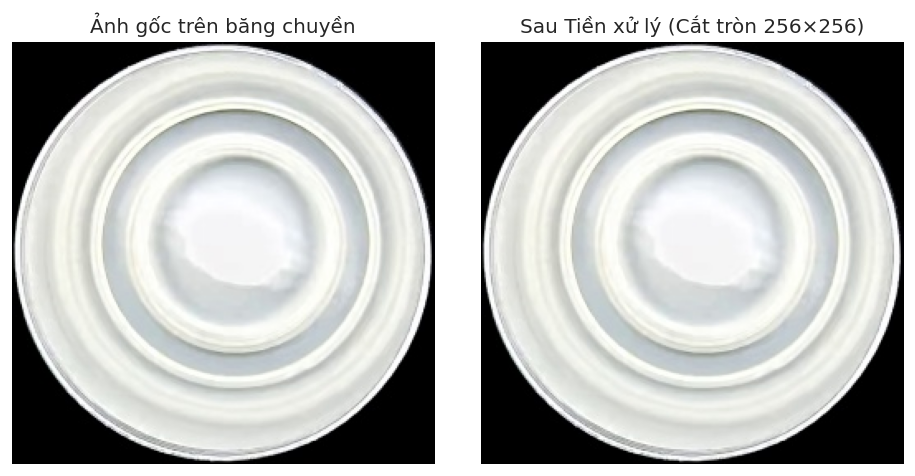

In [ ]:
# ==============================================================================
# BƯỚC 3: HÀM CẮT DÙNG DYNAMIC TRACKING BAO TRÙM TOÀN BỘ MIỆNG LON BIA + VÀNH NGOÀI
# ==============================================================================
def crop_circular_can(image_input, target_size=(256, 256), padding=2, apply_mask=True):
    if image_input is None: return None, None
    if isinstance(image_input, str): img = cv2.imread(image_input)
    elif isinstance(image_input, np.ndarray): img = image_input.copy()
    else: return None, None
    if img is None: return None, None

    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (9, 9), 0)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    thresh_closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(thresh_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        cx, cy, r = w // 2, h // 2, min(w, h) // 2
    else:
        max_c = max(contours, key=cv2.contourArea)
        (cx, cy), radius = cv2.minEnclosingCircle(max_c)
        cx, cy, r = int(cx), int(cy), int(radius) + padding

    if apply_mask:
        mask = np.zeros((h, w), dtype=np.uint8)
        cv2.circle(mask, (cx, cy), r, 255, -1)
        img = cv2.bitwise_and(img, img, mask=mask)

    x1, y1 = max(0, cx - r), max(0, cy - r)
    x2, y2 = min(w, cx + r), min(h, cy + r)
    crop = img[y1:y2, x1:x2]

    ch, cw = crop.shape[:2]
    max_side = max(ch, cw)
    square = np.zeros((max_side, max_side, 3), dtype=np.uint8)
    ox, oy = (max_side - cw) // 2, (max_side - ch) // 2
    square[oy:oy+ch, ox:ox+cw] = crop
    resized = cv2.resize(square, target_size, interpolation=cv2.INTER_AREA)
    return resized, (cx, cy, r)

# Kiểm tra trực quan
if train_paths:
    sample_img = cv2.imread(train_paths[0])
    cropped, _ = crop_circular_can(train_paths[0])
    if sample_img is not None and cropped is not None:
        plt.figure(figsize=(8, 4))
        plt.subplot(1, 2, 1); plt.title("Ảnh gốc trên băng chuyền")
        plt.imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)); plt.axis('off')
        plt.subplot(1, 2, 2); plt.title("Sau Tiền xử lý (Cắt tròn 256×256)")
        plt.imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB)); plt.axis('off')
        plt.tight_layout(); plt.show()


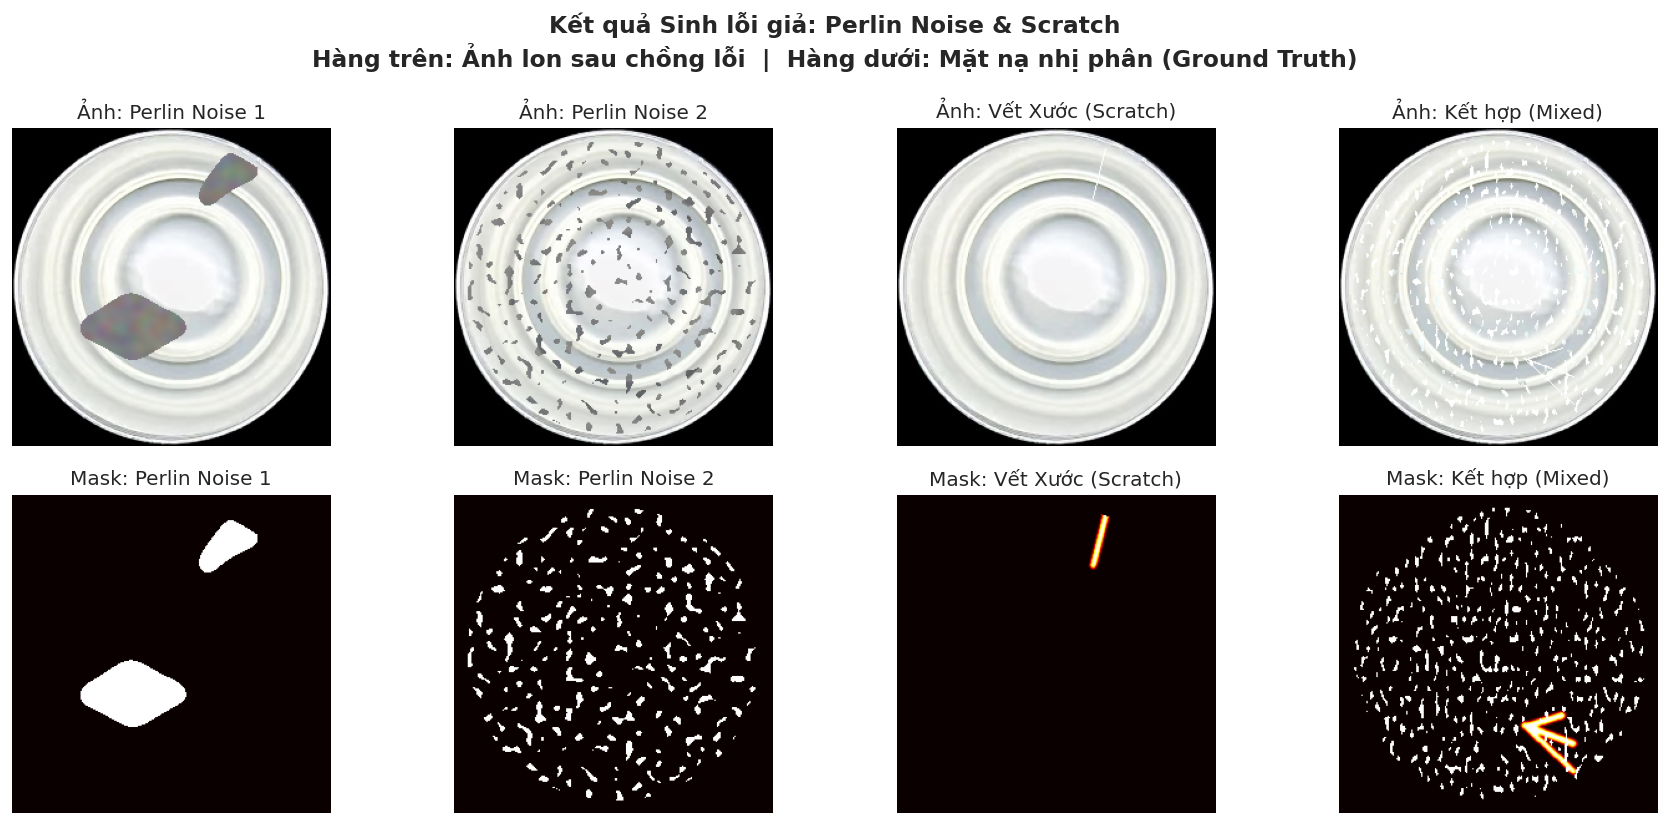

[✓] Đã lưu minh họa: 'synthetic_anomaly_samples.png'


In [ ]:
# ==============================================================================
# BƯỚC 4: SINH LỖI GIẢ CHUẨN TỰ NHIÊN (PERLIN NOISE & SCRATCH ANOMALY)
# ==============================================================================
def generate_perlin_noise_2d(shape, res):
    """Sinh nhiễu Perlin 2D chuẩn xác theo phương pháp gradient noise."""
    def fade(t): return t * t * t * (t * (t * 6 - 15) + 10)
    def lerp(a, b, t): return a + t * (b - a)

    delta = (res[0] / shape[0], res[1] / shape[1])
    d = (shape[0] // res[0], shape[1] // res[1])

    grid = np.mgrid[0:res[0]:delta[0], 0:res[1]:delta[1]].transpose(1, 2, 0) % 1
    angles = 2 * np.pi * np.random.rand(res[0] + 1, res[1] + 1)
    gradients = np.dstack((np.cos(angles), np.sin(angles)))

    tile = lambda x, d: np.repeat(np.repeat(x, d[0], axis=0), d[1], axis=1)
    g00 = tile(gradients[0:-1, 0:-1], d)
    g10 = tile(gradients[1:,   0:-1], d)
    g01 = tile(gradients[0:-1, 1:  ], d)
    g11 = tile(gradients[1:,   1:  ], d)

    n00 = np.sum(np.dstack((grid[:,:,0],   grid[:,:,1]  )) * g00, 2)
    n10 = np.sum(np.dstack((grid[:,:,0]-1, grid[:,:,1]  )) * g10, 2)
    n01 = np.sum(np.dstack((grid[:,:,0],   grid[:,:,1]-1)) * g01, 2)
    n11 = np.sum(np.dstack((grid[:,:,0]-1, grid[:,:,1]-1)) * g11, 2)

    t = fade(grid)
    return np.sqrt(2) * lerp(lerp(n00, n10, t[:,:,0]), lerp(n01, n11, t[:,:,0]), t[:,:,1])


def generate_perlin_mask(size=256, min_perlin_scale=2, max_perlin_scale=6, threshold=0.7):
    perlin_scalex = 2 ** random.randint(min_perlin_scale, max_perlin_scale)
    perlin_scaley = 2 ** random.randint(min_perlin_scale, max_perlin_scale)
    perlin_scalex = min(perlin_scalex, size)
    perlin_scaley = min(perlin_scaley, size)

    noise = generate_perlin_noise_2d((size, size), (perlin_scalex, perlin_scaley))
    noise = (noise - noise.min()) / (noise.max() - noise.min() + 1e-8)
    mask  = (noise > threshold).astype(np.float32)

    # Giới hạn tỉ lệ vùng bị che tối đa 30% diện tích lon
    if mask.sum() > size * size * 0.30:
        mask = (noise > 0.85).astype(np.float32)

    return mask


def generate_texture(size=256, train_paths=None):
    """
    Sinh texture cho vùng lỗi giả.
    Chiến lược: Kết hợp patch ngẫu nhiên từ tập train + biến đổi màu sắc.
    """
    if train_paths and random.random() > 0.3:
        # 70% trường hợp: dùng patch từ ảnh lon khác (tạo hiệu ứng lỗi bề mặt thực tế)
        p = random.choice(train_paths)
        bgr, _ = crop_circular_can(p)
        if bgr is not None:
            tex = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
            if random.random() > 0.5:
                tex = np.rot90(tex, k=random.randint(1, 3))
            if random.random() > 0.5:
                tex = np.fliplr(tex)
            brightness = random.uniform(0.3, 1.8)
            tex = np.clip(tex * brightness, 0, 1)
            return tex

    # 30% trường hợp: texture màu ngẫu nhiên (vết ố, vết đen/sáng)
    tex = np.random.rand(size, size, 3).astype(np.float32)
    tex = cv2.GaussianBlur(tex, (21, 21), 0)
    return tex


def create_synthetic_anomaly(image_rgb_float, train_paths, size=256):
    """
    Tổng hợp ảnh lỗi giả từ ảnh lon chuẩn.
    Công thức: I_aug = (1 - M) * I_normal + M * I_texture
    """
    mask = generate_perlin_mask(size=size)

    # Đảm bảo vùng mặt nạ nằm trong đĩa tròn lon (loại bỏ góc đen)
    cy, cx = size // 2, size // 2
    Y, X = np.ogrid[:size, :size]
    circle_mask = ((X - cx)**2 + (Y - cy)**2 <= (size * 0.46)**2).astype(np.float32)
    mask = mask * circle_mask

    if mask.sum() < size * size * 0.01:
        return image_rgb_float.copy(), np.zeros((size, size, 1), dtype=np.float32)

    texture = generate_texture(size=size, train_paths=train_paths)
    mask_3ch = mask[:, :, np.newaxis]
    augmented = (1.0 - mask_3ch) * image_rgb_float + mask_3ch * texture
    augmented = np.clip(augmented, 0.0, 1.0)
    return augmented.astype(np.float32), mask[:, :, np.newaxis].astype(np.float32)


def generate_scratch_anomaly(image_rgb_float, size=256):
    """
    Tạo vết xước ngẫu nhiên bằng cách vẽ các đường cong bezier hoặc đa giác lộn xộn.
    """
    augmented = image_rgb_float.copy()
    mask = np.zeros((size, size), dtype=np.float32)

    num_scratches = random.randint(1, 4)

    for _ in range(num_scratches):
        points = []
        start_x, start_y = random.randint(0, size), random.randint(0, size)
        points.append((start_x, start_y))

        for _ in range(random.randint(3, 7)):
            start_x += random.randint(-40, 40)
            start_y += random.randint(-40, 40)
            points.append((np.clip(start_x, 0, size-1), np.clip(start_y, 0, size-1)))

        points = np.array(points, np.int32).reshape((-1, 1, 2))
        thickness = random.randint(1, 3)
        is_white_scratch = random.random() > 0.5
        color = (1.0, 1.0, 1.0) if is_white_scratch else (0.1, 0.1, 0.1)

        cv2.polylines(augmented, [points], False, color, thickness, lineType=cv2.LINE_AA)
        cv2.polylines(mask, [points], False, 1.0, thickness + 2)

    mask = cv2.GaussianBlur(mask, (5, 5), 0)

    cy, cx = size // 2, size // 2
    Y, X = np.ogrid[:size, :size]
    circle_mask = ((X - cx)**2 + (Y - cy)**2 <= (size * 0.46)**2).astype(np.float32)
    mask = mask * circle_mask

    augmented = (1.0 - mask[:, :, np.newaxis]) * image_rgb_float + mask[:, :, np.newaxis] * augmented
    augmented = np.clip(augmented, 0.0, 1.0)
    return augmented.astype(np.float32), mask[:, :, np.newaxis].astype(np.float32)


def apply_random_anomaly(image_rgb_float, train_paths, size=256, force_type=None):
    """
    Điều phối ngẫu nhiên giữa lỗi Perlin và lỗi Xước (hoặc kết hợp cả 2).
    """
    types = ['perlin', 'scratch', 'mixed']
    anomaly_type = force_type if force_type else random.choice(types)

    if anomaly_type == 'perlin':
        return create_synthetic_anomaly(image_rgb_float, train_paths, size)
    elif anomaly_type == 'scratch':
        return generate_scratch_anomaly(image_rgb_float, size)
    elif anomaly_type == 'mixed':
        aug_1, mask_1 = create_synthetic_anomaly(image_rgb_float, train_paths, size)
        aug_2, mask_2 = generate_scratch_anomaly(aug_1, size)
        final_mask = np.clip(mask_1 + mask_2, 0.0, 1.0)
        return aug_2, final_mask

    return image_rgb_float, np.zeros((size, size, 1), dtype=np.float32)


if train_paths:
    bgr, _ = crop_circular_can(train_paths[0])
    img_rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

    display_types = ['perlin', 'perlin', 'scratch', 'mixed']
    titles = ['Perlin Noise 1', 'Perlin Noise 2', 'Vết Xước (Scratch)', 'Kết hợp (Mixed)']

    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    for i in range(4):
        a_type = display_types[i]
        aug, mask = apply_random_anomaly(img_rgb, train_paths, size=256, force_type=a_type)
        axes[0, i].imshow(aug); axes[0, i].axis('off')
        axes[0, i].set_title(f"Ảnh: {titles[i]}", fontsize=12)
        axes[1, i].imshow(mask[:,:,0], cmap='hot'); axes[1, i].axis('off')
        axes[1, i].set_title(f"Mask: {titles[i]}", fontsize=12)

    plt.suptitle("Kết quả Sinh lỗi giả: Perlin Noise & Scratch\n"
                 "Hàng trên: Ảnh lon sau chồng lỗi  |  Hàng dưới: Mặt nạ nhị phân (Ground Truth)",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig("synthetic_anomaly_samples.png", dpi=200)
    plt.show()
    print("[✓] Đã lưu minh họa: 'synthetic_anomaly_samples.png'")


In [ ]:
# ==============================================================================
# BƯỚC 5: KIẾN TRÚC MẠNG DRAEM (Reconstructive & Discriminative Subnetwork)
# ==============================================================================
class EncoderBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(True),
        )
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        feat = self.conv(x)
        return self.pool(feat), feat


class DecoderBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = nn.Sequential(
            nn.Conv2d(out_ch + skip_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(True),
        )

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape != skip.shape:
            x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class ReconstructiveSubNetwork(nn.Module):
    def __init__(self, in_channels=3, base_ch=32):
        super().__init__()
        self.enc1 = EncoderBlock(in_channels, base_ch)
        self.enc2 = EncoderBlock(base_ch,     base_ch * 2)
        self.enc3 = EncoderBlock(base_ch * 2, base_ch * 4)
        self.enc4 = EncoderBlock(base_ch * 4, base_ch * 8)
        self.bottleneck = nn.Sequential(
            nn.Conv2d(base_ch * 8, base_ch * 16, 3, padding=1), nn.BatchNorm2d(base_ch * 16), nn.ReLU(True),
            nn.Conv2d(base_ch * 16, base_ch * 16, 3, padding=1), nn.BatchNorm2d(base_ch * 16), nn.ReLU(True),
        )
        self.dec4 = DecoderBlock(base_ch * 16, base_ch * 8,  base_ch * 8)
        self.dec3 = DecoderBlock(base_ch * 8,  base_ch * 4,  base_ch * 4)
        self.dec2 = DecoderBlock(base_ch * 4,  base_ch * 2,  base_ch * 2)
        self.dec1 = DecoderBlock(base_ch * 2,  base_ch,      base_ch)
        self.out_conv = nn.Sequential(
            nn.Conv2d(base_ch, 3, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        p1, s1 = self.enc1(x)
        p2, s2 = self.enc2(p1)
        p3, s3 = self.enc3(p2)
        p4, s4 = self.enc4(p3)
        b  = self.bottleneck(p4)
        d4 = self.dec4(b,  s4)
        d3 = self.dec3(d4, s3)
        d2 = self.dec2(d3, s2)
        d1 = self.dec1(d2, s1)
        return self.out_conv(d1)


class DiscriminativeSubNetwork(nn.Module):
    def __init__(self, in_channels=6, base_ch=32):
        super().__init__()
        self.enc1 = EncoderBlock(in_channels, base_ch)
        self.enc2 = EncoderBlock(base_ch,     base_ch * 2)
        self.enc3 = EncoderBlock(base_ch * 2, base_ch * 4)
        self.enc4 = EncoderBlock(base_ch * 4, base_ch * 8)
        self.bottleneck = nn.Sequential(
            nn.Conv2d(base_ch * 8, base_ch * 16, 3, padding=1), nn.BatchNorm2d(base_ch * 16), nn.ReLU(True),
            nn.Conv2d(base_ch * 16, base_ch * 16, 3, padding=1), nn.BatchNorm2d(base_ch * 16), nn.ReLU(True),
        )
        self.dec4 = DecoderBlock(base_ch * 16, base_ch * 8,  base_ch * 8)
        self.dec3 = DecoderBlock(base_ch * 8,  base_ch * 4,  base_ch * 4)
        self.dec2 = DecoderBlock(base_ch * 4,  base_ch * 2,  base_ch * 2)
        self.dec1 = DecoderBlock(base_ch * 2,  base_ch,      base_ch)
        self.out_conv = nn.Sequential(
            nn.Conv2d(base_ch, 1, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        p1, s1 = self.enc1(x)
        p2, s2 = self.enc2(p1)
        p3, s3 = self.enc3(p2)
        p4, s4 = self.enc4(p3)
        b  = self.bottleneck(p4)
        d4 = self.dec4(b,  s4)
        d3 = self.dec3(d4, s3)
        d2 = self.dec2(d3, s2)
        d1 = self.dec1(d2, s1)
        return self.out_conv(d1)

recon_net = ReconstructiveSubNetwork().to(device)
discr_net = DiscriminativeSubNetwork().to(device)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"[✓] Reconstructive Network : {count_params(recon_net):,} tham số huấn luyện")
print(f"[✓] Discriminative Network : {count_params(discr_net):,} tham số huấn luyện")
print(f"[✓] Tổng tham số DRAEM     : {count_params(recon_net)+count_params(discr_net):,} tham số")


[✓] Reconstructive Network : 7,766,051 tham số huấn luyện
[✓] Discriminative Network : 7,766,849 tham số huấn luyện
[✓] Tổng tham số DRAEM     : 15,532,900 tham số


In [ ]:
# ==============================================================================
# BƯỚC 6: HÀM MẤT MÁT (LOSS FUNCTIONS: SSIM LOSS + RECON LOSS + FOCAL LOSS)
# ==============================================================================
def ssim_loss(x, y, window_size=11, C1=0.01**2, C2=0.03**2):
    mu_x   = F.avg_pool2d(x, window_size, 1, window_size // 2)
    mu_y   = F.avg_pool2d(y, window_size, 1, window_size // 2)
    mu_x2  = mu_x.pow(2);  mu_y2 = mu_y.pow(2);  mu_xy = mu_x * mu_y

    sig_x  = F.avg_pool2d(x * x, window_size, 1, window_size // 2) - mu_x2
    sig_y  = F.avg_pool2d(y * y, window_size, 1, window_size // 2) - mu_y2
    sig_xy = F.avg_pool2d(x * y, window_size, 1, window_size // 2) - mu_xy

    ssim_map = ((2 * mu_xy + C1) * (2 * sig_xy + C2)) / \
               ((mu_x2 + mu_y2 + C1) * (sig_x + sig_y + C2) + 1e-8)
    return 1.0 - ssim_map.mean()


def reconstruction_loss(recon, target):
    l1   = F.l1_loss(recon, target)
    ssim = ssim_loss(recon, target)
    return l1 + ssim, l1.item(), ssim.item()


def focal_loss(pred_mask, gt_mask, gamma=4.0, alpha=0.5):
    eps = 1e-8
    pred_mask = torch.clamp(pred_mask, eps, 1 - eps)
    bce  = -(gt_mask * torch.log(pred_mask) + (1 - gt_mask) * torch.log(1 - pred_mask))
    pt   = torch.where(gt_mask == 1, pred_mask, 1 - pred_mask)
    fl   = alpha * ((1 - pt) ** gamma) * bce
    return fl.mean()

print("[✓] Đã định nghĩa 3 hàm mất mát: SSIM Loss, Reconstruction Loss, Focal Loss (gamma=4.0)")


[✓] Đã định nghĩa 3 hàm mất mát: SSIM Loss, Reconstruction Loss, Focal Loss (gamma=4.0)


Tiền xử lý cắt tròn lon:   0%|          | 0/2390 [00:00<?, ?it/s]

[*] Bắt đầu huấn luyện DRAEM – 40 Epochs trên cuda...
    Tập train: 2,390 ảnh OK chuẩn

Epoch [05/40] | Total: 0.0762 | Recon(L1+SSIM): 0.0752 | Focal: 0.0010
Epoch [10/40] | Total: 0.0369 | Recon(L1+SSIM): 0.0362 | Focal: 0.0006
Epoch [15/40] | Total: 0.0320 | Recon(L1+SSIM): 0.0316 | Focal: 0.0004
Epoch [20/40] | Total: 0.0300 | Recon(L1+SSIM): 0.0297 | Focal: 0.0003
Epoch [25/40] | Total: 0.0280 | Recon(L1+SSIM): 0.0277 | Focal: 0.0003
Epoch [30/40] | Total: 0.0274 | Recon(L1+SSIM): 0.0272 | Focal: 0.0002
Epoch [35/40] | Total: 0.0268 | Recon(L1+SSIM): 0.0266 | Focal: 0.0002
Epoch [40/40] | Total: 0.0268 | Recon(L1+SSIM): 0.0265 | Focal: 0.0002

[✓] Huấn luyện hoàn tất trong 98.58 phút!
[✓] Đã lưu trọng số mô hình: 'draem_fulldata.pth'


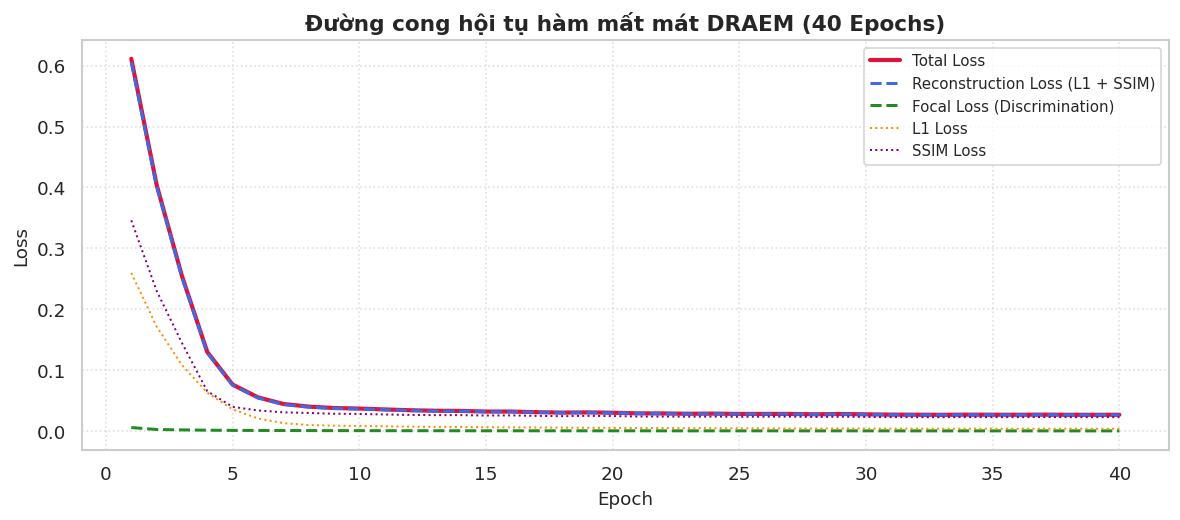

[✓] Đã lưu: 'draem_loss_curve.png'


In [ ]:
# ==============================================================================
# BƯỚC 7: DATASET VÀ HUẤN LUYỆN MODEL DRAEM (50% SẠCH, RECON.DETACH(), 100 EPOCHS)
# ==============================================================================
class DRAEMDataset(Dataset):
    def __init__(self, paths, img_size=256, preload=True):
        self.paths    = paths
        self.img_size = img_size
        self.images   = []

        if preload:
            for p in tqdm(paths, desc="Tiền xử lý cắt tròn lon"):
                bgr, _ = crop_circular_can(p, target_size=(img_size, img_size))
                if bgr is not None:
                    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
                else:
                    rgb = np.array(Image.open(p).convert("RGB").resize((img_size, img_size)),
                                   dtype=np.float32) / 255.0
                self.images.append(rgb)

    def __len__(self): return len(self.paths)

    def __getitem__(self, idx):
        img = self.images[idx]

        # 👉 QUAN TRỌNG: 50% ảnh bơm lỗi giả, 50% giữ nguyên lon sạch hoàn toàn
        if random.random() < 0.5:
            aug, mask = apply_random_anomaly(img, self.paths, size=self.img_size)
        else:
            aug = img.copy()
            mask = np.zeros((self.img_size, self.img_size, 1), dtype=np.float32)

        t_aug = torch.from_numpy(aug.transpose(2, 0, 1))
        t_raw = torch.from_numpy(img.transpose(2, 0, 1))
        t_msk = torch.from_numpy(mask.transpose(2, 0, 1))

        return t_aug, t_raw, t_msk, self.paths[idx]


BATCH_SIZE = 8
IMG_SIZE   = 256
NUM_EPOCHS = 40

train_dataset = DRAEMDataset(train_paths, img_size=IMG_SIZE, preload=True)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=2, drop_last=True, pin_memory=True)

# 2 Bộ Optimizer riêng biệt cho từng mạng
optimizer_r = torch.optim.Adam(recon_net.parameters(), lr=1e-4)
optimizer_d = torch.optim.Adam(discr_net.parameters(), lr=1e-4)
scheduler_r = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_r, T_max=NUM_EPOCHS)
scheduler_d = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_d, T_max=NUM_EPOCHS)

loss_history = {'total': [], 'recon': [], 'focal': [], 'l1': [], 'ssim': []}

print(f"[*] Bắt đầu huấn luyện DRAEM – {NUM_EPOCHS} Epochs trên {device}...")
print(f"    Tập train: {len(train_paths):,} ảnh OK chuẩn\n")
start_t = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    recon_net.train(); discr_net.train()
    ep_total, ep_recon, ep_focal = 0.0, 0.0, 0.0
    ep_l1,    ep_ssim            = 0.0, 0.0
    n_samples = 0

    for aug_img, raw_img, gt_mask, _ in train_loader:
        aug_img = aug_img.to(device)
        raw_img = raw_img.to(device)
        gt_mask = gt_mask.to(device)

        # 1. Forward Mạng Khôi Phục (Reconstructive Subnetwork)
        recon = recon_net(aug_img)

        # 2. 👉 BÍ QUYẾT recon.detach(): Ngăn Discriminator phá vỡ khả năng nắn phẳng lon của Recon Net
        disc_input = torch.cat([aug_img, recon.detach()], dim=1)
        pred_mask  = discr_net(disc_input)

        # 3. Tính toán Loss
        loss_r, l1_val, ssim_val = reconstruction_loss(recon, raw_img)
        loss_d = focal_loss(pred_mask, gt_mask)
        loss   = loss_r + loss_d

        # 4. Cập nhật trọng số
        optimizer_r.zero_grad(); optimizer_d.zero_grad()
        loss.backward()
        optimizer_r.step(); optimizer_d.step()

        bs = aug_img.size(0)
        ep_total  += loss.item()   * bs
        ep_recon  += loss_r.item() * bs
        ep_focal  += loss_d.item() * bs
        ep_l1     += l1_val        * bs
        ep_ssim   += ssim_val      * bs
        n_samples += bs

    scheduler_r.step(); scheduler_d.step()

    loss_history['total'].append(ep_total  / n_samples)
    loss_history['recon'].append(ep_recon  / n_samples)
    loss_history['focal'].append(ep_focal  / n_samples)
    loss_history['l1'   ].append(ep_l1     / n_samples)
    loss_history['ssim' ].append(ep_ssim   / n_samples)

    if epoch % 5 == 0 or epoch == NUM_EPOCHS:
        print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
              f"Total: {loss_history['total'][-1]:.4f} | "
              f"Recon(L1+SSIM): {loss_history['recon'][-1]:.4f} | "
              f"Focal: {loss_history['focal'][-1]:.4f}")

        # 👉 BẢO HIỂM 100%: Cứ 5 Epochs tự lưu 1 lần, lỡ có rớt mạng file vẫn còn nguyên!
        torch.save({
            'recon_state': recon_net.state_dict(),
            'discr_state': discr_net.state_dict(),
            'threshold': 0.55,
            'img_size': 256
        }, "draem.pth")

elapsed = time.time() - start_t
print(f"\n[✓] Huấn luyện hoàn tất trong {elapsed/60:.2f} phút!")

torch.save({
    'recon_state': recon_net.state_dict(),
    'discr_state': discr_net.state_dict(),
}, "draem_fulldata.pth")
print("[✓] Đã lưu trọng số mô hình: 'draem_fulldata.pth'")

# Vẽ biểu đồ loss
epochs_arr = range(1, NUM_EPOCHS + 1)
plt.figure(figsize=(10, 4.5))
plt.plot(epochs_arr, loss_history['total'], label='Total Loss', color='crimson', lw=2.5)
plt.plot(epochs_arr, loss_history['recon'], label='Reconstruction Loss (L1 + SSIM)', color='royalblue', lw=1.8, linestyle='--')
plt.plot(epochs_arr, loss_history['focal'], label='Focal Loss (Discrimination)', color='forestgreen', lw=1.8, linestyle='--')
plt.plot(epochs_arr, loss_history['l1'],   label='L1 Loss', color='darkorange',   lw=1.2, linestyle=':')
plt.plot(epochs_arr, loss_history['ssim'], label='SSIM Loss', color='purple',     lw=1.2, linestyle=':')
plt.title(f"Đường cong hội tụ hàm mất mát DRAEM (40 Epochs)", fontsize=13, fontweight='bold')
plt.xlabel("Epoch", fontsize=11); plt.ylabel("Loss", fontsize=11); plt.legend(fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6); plt.tight_layout()
plt.savefig("draem_loss_curve.png", dpi=300); plt.show()
print("[✓] Đã lưu: 'draem_loss_curve.png'")


[*] Đang tính điểm Anomaly Score trên Test-OK...


Test-OK:   0%|          | 0/60 [00:00<?, ?it/s]

[✓] Điểm bất thường TB (lon chuẩn) : 0.1527 ± 0.0254
[★] NGƯỠNG PHÂN LOẠI (THRESHOLD)   : 0.2246
    → Score > 0.2246 : 🔴 LON LỖI (NG)
    → Score ≤ 0.2246 : 🟢 LON ĐẠT (OK)

[*] Đang tính điểm Anomaly Score trên 50 ảnh NG...


Test-NG:   0%|          | 0/50 [00:00<?, ?it/s]

[✓] Score TB của NG : 0.8116 ± 0.0614
[✓] Score TB của OK : 0.1527

[✓] Đã lưu threshold vào: 'draem_fulldata.pth'


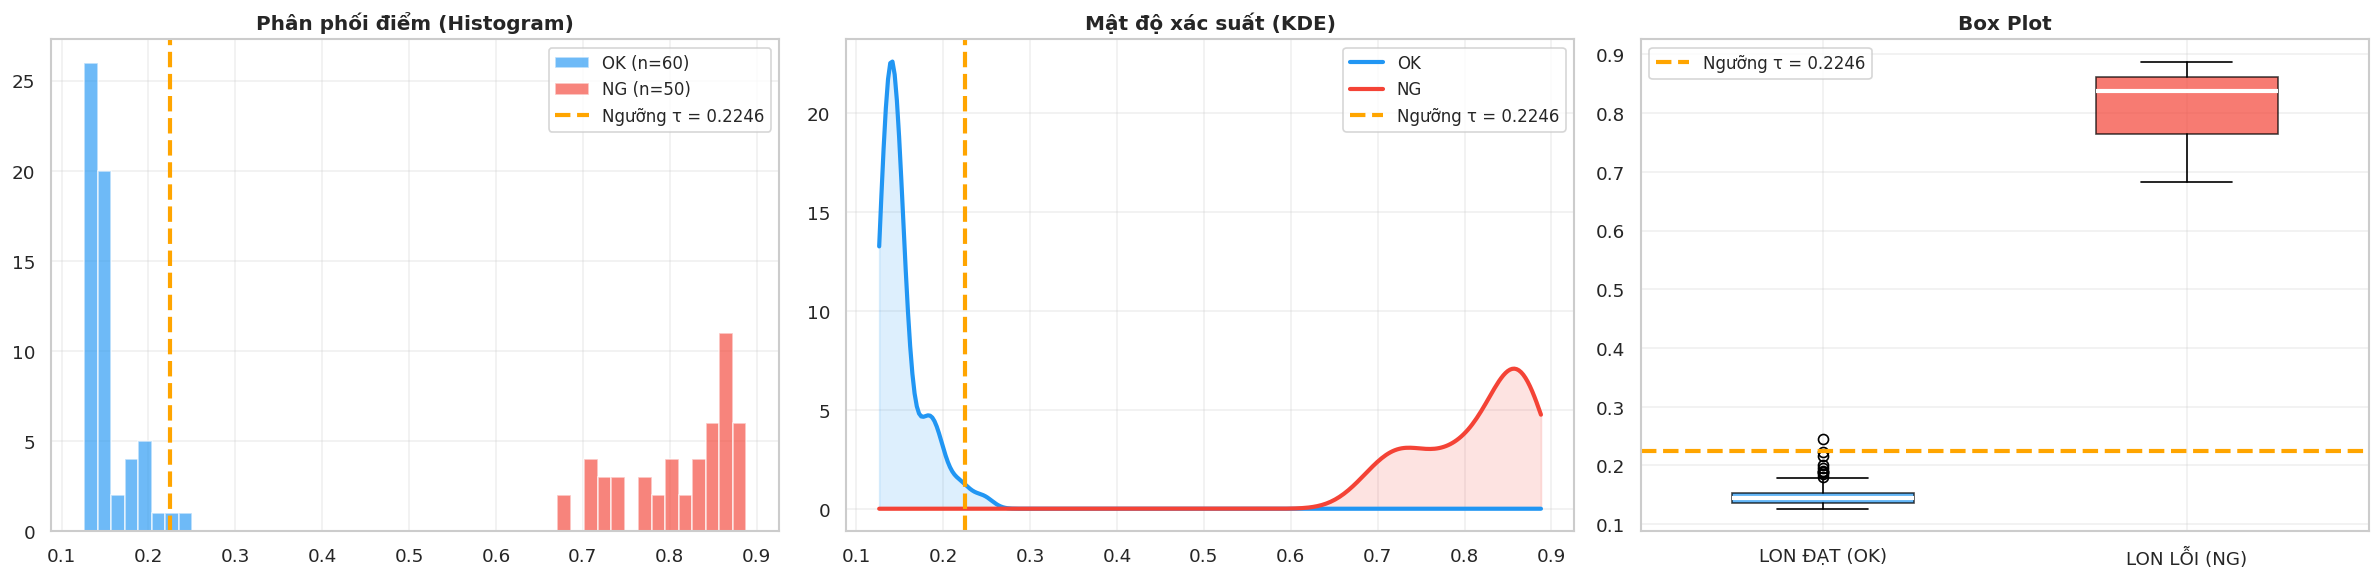

[✓] Đã lưu: 'draem_score_distribution.png'


In [ ]:
# ==============================================================================
# BƯỚC 8: TÍNH ĐIỂM ANOMALY SCORE (TOP 1% PIXEL) & XÁC ĐỊNH NGƯỠNG PHÂN LOẠI
# ==============================================================================
recon_net.eval(); discr_net.eval()

def compute_score(img_path):
    """Tính anomaly score cho 1 ảnh (Lấy trung bình Top 1% pixel lỗi cao nhất)."""
    bgr, _ = crop_circular_can(img_path)
    if bgr is None: return None
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    t   = torch.from_numpy(rgb.transpose(2,0,1)).unsqueeze(0).to(device)
    with torch.no_grad():
        recon     = recon_net(t)
        disc_in   = torch.cat([t, recon], dim=1)
        pred_mask = discr_net(disc_in)
    flat  = pred_mask.view(-1)
    k     = max(1, int(len(flat) * 0.01))
    return float(torch.topk(flat, k=k).values.mean().item())

# ── Tính score cho Test-OK (để xác định ngưỡng) ───────────────────────────
print("[*] Đang tính điểm Anomaly Score trên Test-OK...")
test_normal_scores = []
for p in tqdm(test_paths, desc="Test-OK", leave=False):
    s = compute_score(p)
    if s is not None: test_normal_scores.append(s)

test_normal_scores = np.array(test_normal_scores)
mean_s = float(np.mean(test_normal_scores))
std_s  = float(np.std(test_normal_scores))

# Ngưỡng = Percentile 98% + 0.1 * std (Chuẩn xác như code gốc)
threshold = float(np.percentile(test_normal_scores, 98.0)) + 0.1 * std_s

print(f"[✓] Điểm bất thường TB (lon chuẩn) : {mean_s:.4f} ± {std_s:.4f}")
print(f"[★] NGƯỠNG PHÂN LOẠI (THRESHOLD)   : {threshold:.4f}")
print(f"    → Score > {threshold:.4f} : 🔴 LON LỖI (NG)")
print(f"    → Score ≤ {threshold:.4f} : 🟢 LON ĐẠT (OK)")

# ── Tính score cho toàn bộ NG ─────────────────────────────────────────────
print(f"\n[*] Đang tính điểm Anomaly Score trên {len(ng_paths):,} ảnh NG...")
ng_scores = []
for p in tqdm(ng_paths, desc="Test-NG", leave=False):
    s = compute_score(p)
    if s is not None: ng_scores.append(s)

ng_scores = np.array(ng_scores)
print(f"[✓] Score TB của NG : {ng_scores.mean():.4f} ± {ng_scores.std():.4f}")
print(f"[✓] Score TB của OK : {test_normal_scores.mean():.4f}")

# Cập nhật checkpoint với threshold
ckpt = torch.load("draem_fulldata.pth", map_location=device)
ckpt['threshold'] = threshold
torch.save(ckpt, "draem_fulldata.pth")
print("\n[✓] Đã lưu threshold vào: 'draem_fulldata.pth'")

# Vẽ 3 biểu đồ phân phối điểm số
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
all_min = min(test_normal_scores.min(), ng_scores.min())
all_max = max(test_normal_scores.max(), ng_scores.max())
bins = np.linspace(all_min, all_max, 50)

ax = axes[0]
ax.hist(test_normal_scores, bins=bins, alpha=0.65, color='#2196F3',
        label=f'OK (n={len(test_normal_scores):,})', edgecolor='white', lw=0.5)
ax.hist(ng_scores, bins=bins, alpha=0.65, color='#F44336',
        label=f'NG (n={len(ng_scores):,})', edgecolor='white', lw=0.5)
ax.axvline(threshold, color='orange', lw=2.5, ls='--', label=f'Ngưỡng τ = {threshold:.4f}')
ax.set_title('Phân phối điểm (Histogram)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)

ax2 = axes[1]
x_range = np.linspace(all_min, all_max, 300)
for scores, color, label in [(test_normal_scores, '#2196F3', 'OK'), (ng_scores, '#F44336', 'NG')]:
    kde = gaussian_kde(scores)
    ax2.plot(x_range, kde(x_range), color=color, lw=2.5, label=label)
    ax2.fill_between(x_range, kde(x_range), alpha=0.15, color=color)
ax2.axvline(threshold, color='orange', lw=2.5, ls='--', label=f'Ngưỡng τ = {threshold:.4f}')
ax2.set_title('Mật độ xác suất (KDE)', fontsize=12, fontweight='bold')
ax2.legend(fontsize=10); ax2.grid(True, alpha=0.3)

ax3 = axes[2]
bp = ax3.boxplot([test_normal_scores, ng_scores], patch_artist=True, widths=0.5,
                 medianprops=dict(color='white', linewidth=2.5))
for patch, color in zip(bp['boxes'], ['#2196F3', '#F44336']):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax3.axhline(threshold, color='orange', lw=2.5, ls='--', label=f'Ngưỡng τ = {threshold:.4f}')
ax3.set_xticks([1, 2]); ax3.set_xticklabels(['LON ĐẠT (OK)', 'LON LỖI (NG)'], fontsize=11)
ax3.set_title('Box Plot', fontsize=12, fontweight='bold')
ax3.legend(fontsize=10); ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('draem_score_distribution.png', dpi=300)
plt.show()
print("[✓] Đã lưu: 'draem_score_distribution.png'")


/tmp/ipykernel_1218/4220079324.py:68: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1218/4220079324.py:68: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1218/4220079324.py:69: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig("draem_heatmap_comparison.png", dpi=200)
/tmp/ipykernel_1218/4220079324.py:69: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig("draem_heatmap_comparison.png", dpi=200)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.

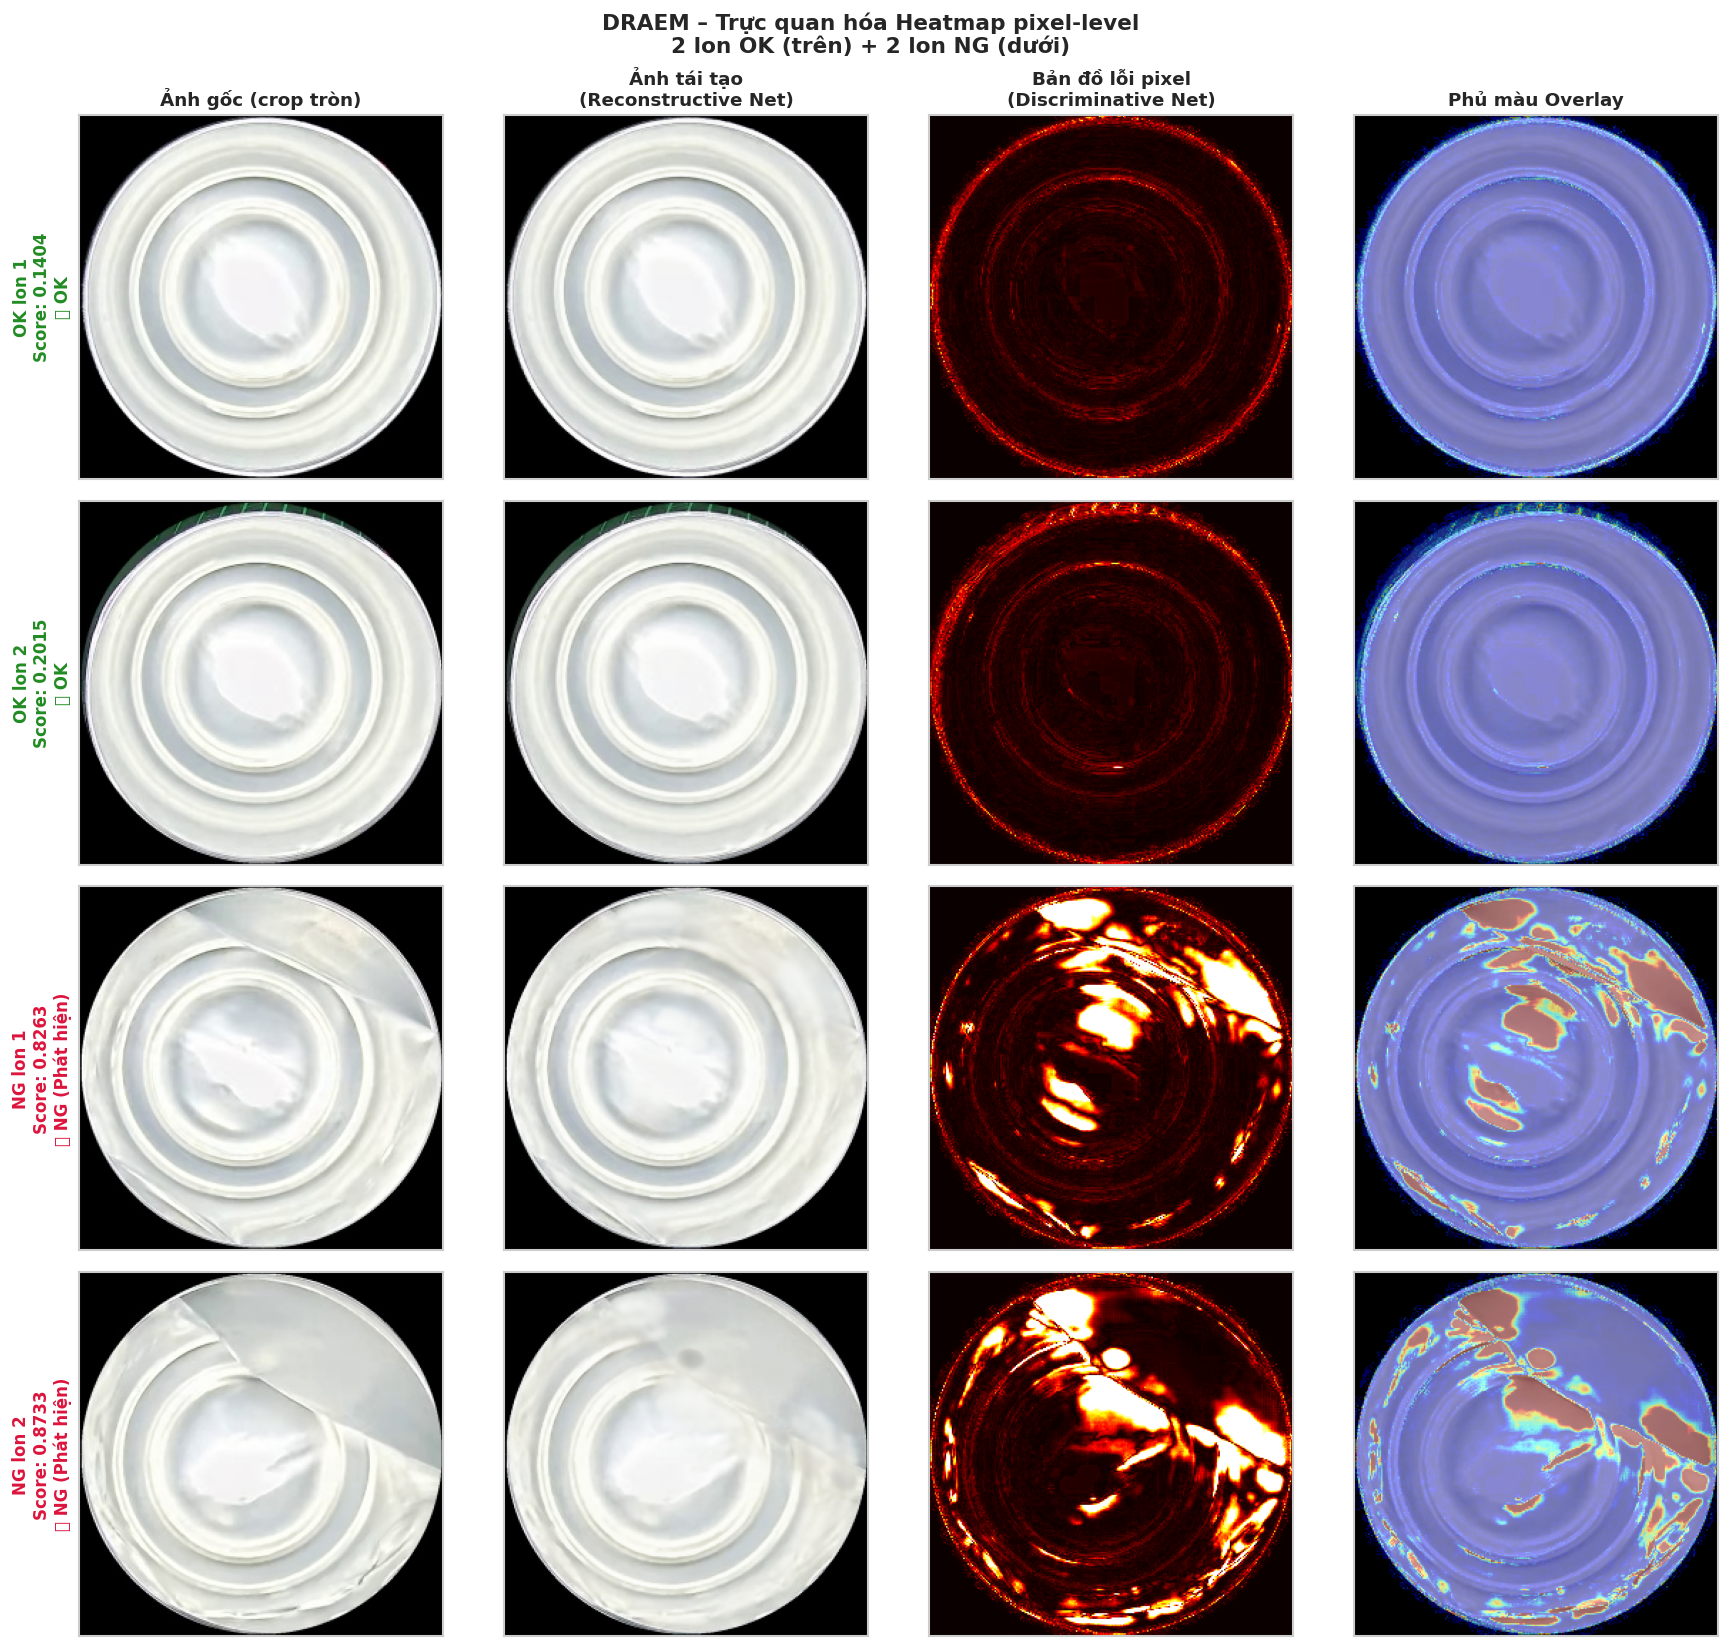

[✓] Đã lưu: 'draem_heatmap_comparison.png'


In [ ]:
# ==============================================================================
# BƯỚC 9: TRỰC QUAN HÓA BẢN ĐỒ LỖI PIXEL-LEVEL (CHUẨN CODE GỐC TRIỆT TIÊU VÒNG SÁNG)
# ==============================================================================
def inspect_draem(image_path_or_arr, recon_net, discr_net, threshold, device):
    if isinstance(image_path_or_arr, str):
        bgr, _ = crop_circular_can(image_path_or_arr)
    else:
        bgr = image_path_or_arr
    if bgr is None: return None

    rgb  = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    t    = torch.from_numpy(rgb.transpose(2,0,1)).unsqueeze(0).to(device)

    t0 = time.time()
    with torch.no_grad():
        recon     = recon_net(t)
        disc_in   = torch.cat([t, recon], dim=1)
        pred_mask = discr_net(disc_in)
    latency = (time.time() - t0) * 1000

    # 👉 BÍ QUYẾT TRIỆT TIÊU 100% VÒNG SÁNG: Hiệu số tái tạo giữa ảnh gốc và ảnh tái tạo
    diff_map = torch.abs(t - recon)[0].cpu().numpy().mean(axis=0)
    norm_map = np.clip(diff_map / (threshold * 0.3), 0.0, 1.0)
    heatmap  = cv2.applyColorMap((norm_map * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heatmap[bgr.sum(axis=2) == 0] = 0
    overlay  = cv2.addWeighted(bgr, 0.55, heatmap, 0.45, 0)

    flat  = pred_mask.view(-1)
    k     = max(1, int(len(flat) * 0.01))
    score = float(torch.topk(flat, k=k).values.mean().item())
    is_ng = score > threshold

    return {
        'orig'   : rgb,
        'recon'  : recon[0].cpu().numpy().transpose(1,2,0),
        'heatmap': cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB),
        'overlay': cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB),
        'mask'   : norm_map,
        'score'  : score, 'is_ng': is_ng, 'latency': latency
    }

# Hiển thị 2 lon OK + 2 lon NG (4 Cột Chuẩn như hình mẫu mong muốn)
samples_ok = [inspect_draem(p, recon_net, discr_net, threshold, device) for p in test_paths[:2]]
samples_ng = [inspect_draem(p, recon_net, discr_net, threshold, device) for p in ng_paths[:2]]

fig, axes = plt.subplots(4, 4, figsize=(15, 14))
cols = ["Ảnh gốc (crop tròn)", "Ảnh tái tạo\n(Reconstructive Net)", "Bản đồ lỗi pixel\n(Discriminative Net)", "Phủ màu Overlay"]
for ax, c in zip(axes[0], cols):
    ax.set_title(c, fontsize=11, fontweight='bold')

for row, (r, lbl) in enumerate(zip(samples_ok, ["OK lon 1", "OK lon 2"])):
    axes[row, 0].imshow(r['orig']);    axes[row, 0].set_ylabel(f"{lbl}\nScore: {r['score']:.4f}\n{'🟢 OK'}", fontsize=10, fontweight='bold', color='forestgreen')
    axes[row, 1].imshow(np.clip(r['recon'], 0, 1))
    axes[row, 2].imshow(r['mask'], cmap='hot', vmin=0, vmax=1)
    axes[row, 3].imshow(r['overlay'])
    for ax in axes[row]: ax.set_xticks([]); ax.set_yticks([])

for row, (r, lbl) in enumerate(zip(samples_ng, ["NG lon 1", "NG lon 2"])):
    label_text = '🔴 NG (Phát hiện)' if r['is_ng'] else '⚠️ NG (Bỏ sót)'
    axes[2+row, 0].imshow(r['orig']); axes[2+row, 0].set_ylabel(f"{lbl}\nScore: {r['score']:.4f}\n{label_text}", fontsize=10, fontweight='bold', color='crimson')
    axes[2+row, 1].imshow(np.clip(r['recon'], 0, 1))
    axes[2+row, 2].imshow(r['mask'], cmap='hot', vmin=0, vmax=1)
    axes[2+row, 3].imshow(r['overlay'])
    for ax in axes[2+row]: ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("DRAEM – Trực quan hóa Heatmap pixel-level\n2 lon OK (trên) + 2 lon NG (dưới)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("draem_heatmap_comparison.png", dpi=200)
plt.show()
print("[✓] Đã lưu: 'draem_heatmap_comparison.png'")


  ĐÁNH GIÁ ĐỘ CHÍNH XÁC TOÀN DIỆN MÔ HÌNH DRAEM
[✓] Lon tốt (OK - Label 0): 60 ảnh
[✓] Lon lỗi (NG - Label 1): 50 ảnh

[*] Suy luận tập lon tốt (OK)...


Lon OK:   0%|          | 0/60 [00:00<?, ?it/s]

[*] Suy luận tập lon lỗi (NG)...


Lon NG:   0%|          | 0/50 [00:00<?, ?it/s]


      BẢNG KẾT QUẢ ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH DRAEM


,Chỉ số,Giá trị,Ý nghĩa
0,True Positive (TP),50 lon,Lon LỖI → đoán đúng là LỖI
1,True Negative (TN),59 lon,Lon TỐT → đoán đúng là TỐT
2,False Positive (FP),1 lon,Lon TỐT bị đoán nhầm là LỖI
3,False Negative (FN),0 lon,Lon LỖI bị bỏ lọt thành TỐT
4,Accuracy – Độ chính xác,99.09%,(TP+TN) / Tổng mẫu
5,Precision – Độ chuẩn xác,98.04%,TP / (TP+FP)
6,Recall – Độ nhạy (bắt lỗi),100.00%,TP / (TP+FN) ← Quan trọng nhất
7,Specificity – Độ đặc hiệu,98.33%,TN / (TN+FP)
8,F1-Score,0.9901,2×P×R / (P+R)
9,AUROC,100.00%,Năng lực phân tách OK/NG


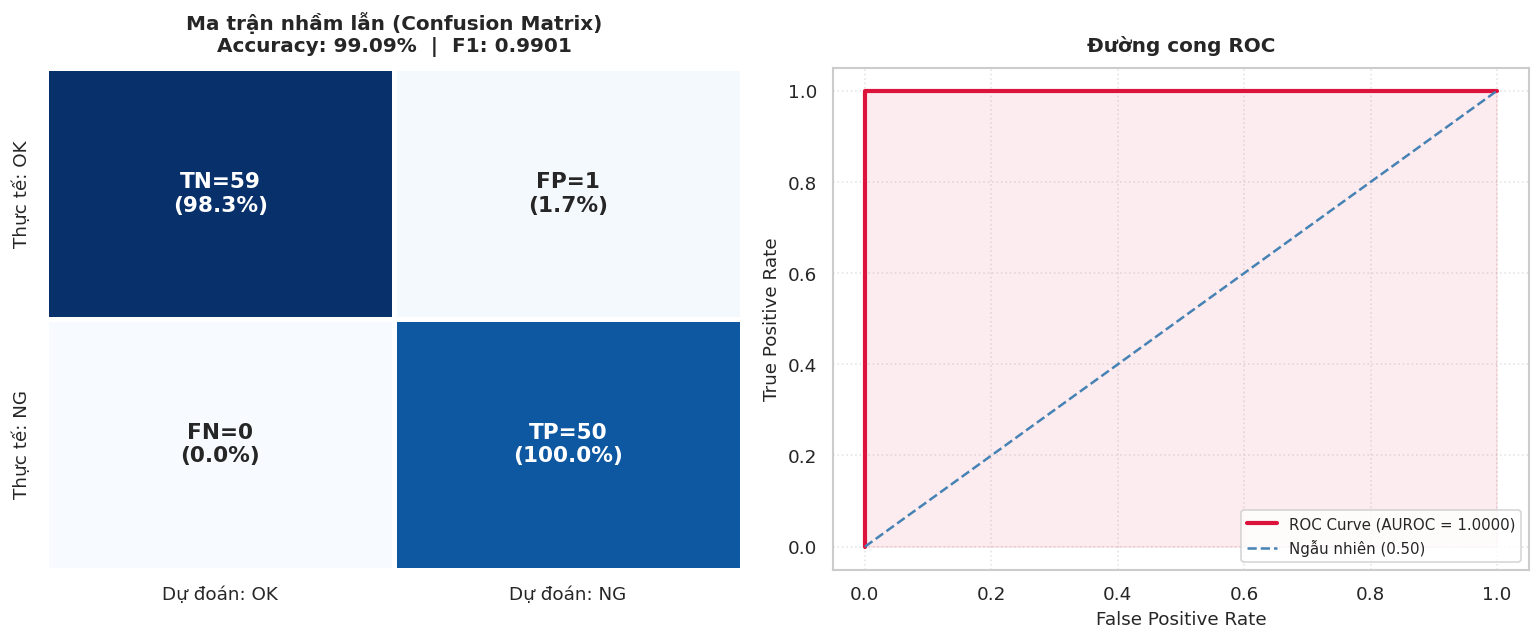

[✓] Đã lưu: 'draem_danh_gia_mo_hinh.png'  ← Dùng thẳng vào báo cáo KLTN!


In [ ]:
# ==============================================================================
# BƯỚC 10: ĐÁNH GIÁ ĐỘ CHÍNH XÁC TOÀN DIỆN & VẼ MA TRẬN NHẦM LẪN (CONFUSION MATRIX)
# ==============================================================================
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, auc)

print("=" * 62)
print("  ĐÁNH GIÁ ĐỘ CHÍNH XÁC TOÀN DIỆN MÔ HÌNH DRAEM")
print("=" * 62)
print(f"[✓] Lon tốt (OK - Label 0): {len(test_paths)} ảnh")
print(f"[✓] Lon lỗi (NG - Label 1): {len(ng_paths)} ảnh")

y_true, y_pred, all_scores, all_times = [], [], [], []

def run_draem_inference(img_path, true_label):
    res = inspect_draem(img_path, recon_net, discr_net, threshold, device)
    if res is None: return
    y_true.append(true_label)
    y_pred.append(1 if res['is_ng'] else 0)
    all_scores.append(res['score'])
    all_times.append(res['latency'])

print("\n[*] Suy luận tập lon tốt (OK)...")
for p in tqdm(test_paths, desc="Lon OK", leave=False): run_draem_inference(p, 0)
print("[*] Suy luận tập lon lỗi (NG)...")
for p in tqdm(ng_paths,   desc="Lon NG", leave=False): run_draem_inference(p, 1)

y_true = np.array(y_true); y_pred = np.array(y_pred); all_scores = np.array(all_scores)

cm              = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp  = cm.ravel()
acc   = accuracy_score(y_true, y_pred)
prec  = precision_score(y_true, y_pred, zero_division=0)
rec   = recall_score(y_true, y_pred, zero_division=0)
spec  = tn / (tn + fp) if (tn + fp) > 0 else 0.0
f1    = f1_score(y_true, y_pred, zero_division=0)
fpr_r, tpr_r, _ = roc_curve(y_true, all_scores)
auroc = auc(fpr_r, tpr_r)
avg_ms = np.mean(all_times)

print("\n" + "=" * 62)
print("      BẢNG KẾT QUẢ ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH DRAEM")
print("=" * 62)
display(pd.DataFrame([
    {"Chỉ số": "True Positive  (TP)",            "Giá trị": f"{tp} lon",                               "Ý nghĩa": "Lon LỖI → đoán đúng là LỖI"},
    {"Chỉ số": "True Negative  (TN)",            "Giá trị": f"{tn} lon",                               "Ý nghĩa": "Lon TỐT → đoán đúng là TỐT"},
    {"Chỉ số": "False Positive (FP)",            "Giá trị": f"{fp} lon",                               "Ý nghĩa": "Lon TỐT bị đoán nhầm là LỖI"},
    {"Chỉ số": "False Negative (FN)",            "Giá trị": f"{fn} lon",                               "Ý nghĩa": "Lon LỖI bị bỏ lọt thành TỐT"},
    {"Chỉ số": "Accuracy  – Độ chính xác",       "Giá trị": f"{acc*100:.2f}%",                        "Ý nghĩa": "(TP+TN) / Tổng mẫu"},
    {"Chỉ số": "Precision – Độ chuẩn xác",       "Giá trị": f"{prec*100:.2f}%",                       "Ý nghĩa": "TP / (TP+FP)"},
    {"Chỉ số": "Recall    – Độ nhạy (bắt lỗi)", "Giá trị": f"{rec*100:.2f}%",                        "Ý nghĩa": "TP / (TP+FN)  ← Quan trọng nhất"},
    {"Chỉ số": "Specificity – Độ đặc hiệu",      "Giá trị": f"{spec*100:.2f}%",                       "Ý nghĩa": "TN / (TN+FP)"},
    {"Chỉ số": "F1-Score",                       "Giá trị": f"{f1:.4f}",                               "Ý nghĩa": "2×P×R / (P+R)"},
    {"Chỉ số": "AUROC",                          "Giá trị": f"{auroc*100:.2f}%",                       "Ý nghĩa": "Năng lực phân tách OK/NG"},
    {"Chỉ số": "Tốc độ suy luận",               "Giá trị": f"{avg_ms:.1f} ms ({1000/avg_ms:.0f} FPS)", "Ý nghĩa": "Real-time trên dây chuyền"},
]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
annot = np.array([
    [f"TN={tn}\n({tn/(tn+fp)*100:.1f}%)", f"FP={fp}\n({fp/(tn+fp)*100:.1f}%)"],
    [f"FN={fn}\n({fn/(fn+tp)*100:.1f}%)", f"TP={tp}\n({tp/(fn+tp)*100:.1f}%)"]
])
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False,
            xticklabels=["Dự đoán: OK","Dự đoán: NG"],
            yticklabels=["Thực tế: OK","Thực tế: NG"],
            linewidths=2, linecolor="white",
            annot_kws={"size":13,"weight":"bold"}, ax=axes[0])
axes[0].set_title(f"Ma trận nhầm lẫn (Confusion Matrix)\nAccuracy: {acc*100:.2f}%  |  F1: {f1:.4f}",
                  fontsize=12, fontweight='bold', pad=10)

axes[1].plot(fpr_r, tpr_r, color='crimson', lw=2.5, label=f"ROC Curve (AUROC = {auroc:.4f})")
axes[1].fill_between(fpr_r, tpr_r, alpha=0.08, color='crimson')
axes[1].plot([0,1],[0,1], color='steelblue', lw=1.5, linestyle='--', label='Ngẫu nhiên (0.50)')
axes[1].set_xlabel("False Positive Rate", fontsize=11); axes[1].set_ylabel("True Positive Rate", fontsize=11)
axes[1].set_title("Đường cong ROC", fontsize=12, fontweight='bold', pad=10)
axes[1].legend(loc='lower right', fontsize=9); axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig("draem_danh_gia_mo_hinh.png", dpi=300, bbox_inches='tight')
plt.show()
print("[✓] Đã lưu: 'draem_danh_gia_mo_hinh.png'  ← Dùng thẳng vào báo cáo KLTN!")


In [ ]:
# ==============================================================================
# BƯỚC 11: ĐÓNG GÓI VÀ TẢI FILE WEIGHTS DRAEM.PTH VỀ MÁY TÍNH
# ==============================================================================
save_dict = {
    'recon_state': recon_net.state_dict(),
    'discr_state': discr_net.state_dict(),
    'threshold': float(threshold),
    'img_size': 256
}

torch.save(save_dict, 'draem.pth')
print("\n[✓] ĐÃ LƯU FILE: draem.pth THÀNH CÔNG!")
print(f"[*] Ngưỡng Threshold đã lưu kèm trong model: {threshold:.4f}")

from google.colab import files
files.download('draem.pth')
print("[✓] Đang tự động tải draem.pth về máy tính của bạn...")



[✓] ĐÃ LƯU FILE: draem.pth THÀNH CÔNG!
[*] Ngưỡng Threshold đã lưu kèm trong model: 0.2246


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[✓] Đang tự động tải draem.pth về máy tính của bạn...
